In [1]:
%matplotlib inline
#import pandas as pd
import polars as pl
import numpy as np
from pathlib import Path
import networkx as nx
import matplotlib.pyplot as plt


In [ ]:
# load multiple countries for comparison

vdem_raw = pl.scan_csv(
    Path("V-Dem-CY-Full+Others-v16.csv"),
    infer_schema_length=False
)

# Countries selected deliberately:
#   China      — the actor spreading disinformation (your thesis subject)
#   Taiwan     — primary target; high resilience case (your Taiwan chapter)
#   United States — major non-BRI democracy; comparison baseline
#   Ethiopia   — BRI recipient in Africa; tests whether BRI correlates with
#                deteriorating information environment
#   Hungary    — EU democracy with documented democratic backsliding;
#                shows the pattern is not China-unique

COUNTRIES = ['China', 'Taiwan', 'United States of America', 'Ethiopia', 'Hungary']

COLS = [
    'country_name', 'year',
    'v2smgovdom',   # Government spreads false info domestically
    'v2smgovab',    # Government spreads false info abroad
    'v2smpardom',   # Party spreads false info domestically
    'v2smparab',    # Party spreads false info abroad
    'v2smfordom',   # Foreign govts spread false info domestically: This measures what TARGET countries experience — Taiwan's score here reflects Chinese operations
]

vdem = (vdem_raw
    .select([pl.col(c) for c in COLS])
    .filter(pl.col('country_name').is_in(COUNTRIES))
    .with_columns([
        pl.col('year').cast(pl.Int32),
        pl.col('v2smgovdom').cast(pl.Float64),
        pl.col('v2smgovab').cast(pl.Float64),
        pl.col('v2smpardom').cast(pl.Float64),
        pl.col('v2smparab').cast(pl.Float64),
        pl.col('v2smfordom').cast(pl.Float64),
    ])
    .filter(pl.col('year') >= 2000)
    .drop_nulls()
    .sort(['country_name', 'year'])
    .collect()
)

# Convert to pandas for plotting — easier with multi-country line charts
df = vdem.to_pandas()

print(f"Countries loaded: {df['country_name'].unique()}")
print(f"Year range: {df['year'].min()} – {df['year'].max()}")
print(f"Rows: {len(df)}")
df.head(10)

Countries loaded: <ArrowStringArray>
['China', 'Ethiopia', 'Hungary', 'Taiwan', 'United States of America']
Length: 5, dtype: str
Year range: 2000 – 2025
Rows: 130


,country_name,year,v2smgovdom,v2smgovab,v2smpardom,v2smparab,v2smfordom
0,China,2000,-1.106,-1.554,-0.885,-1.663,-0.78
1,China,2001,-1.106,-1.554,-0.885,-1.663,-0.78
2,China,2002,-1.106,-1.554,-0.885,-1.663,-0.78
3,China,2003,-1.106,-1.554,-0.885,-1.663,-0.78
4,China,2004,-1.106,-1.554,-0.885,-1.663,-0.78
5,China,2005,-1.106,-1.112,-0.885,-1.290,-0.78
6,China,2006,-1.106,-1.112,-0.885,-1.290,-0.78
7,China,2007,-1.106,-1.112,-0.885,-1.290,-0.78
8,China,2008,-1.106,-1.112,-0.885,-1.290,-0.78
9,China,2009,-1.106,-1.527,-0.885,-1.604,-0.78


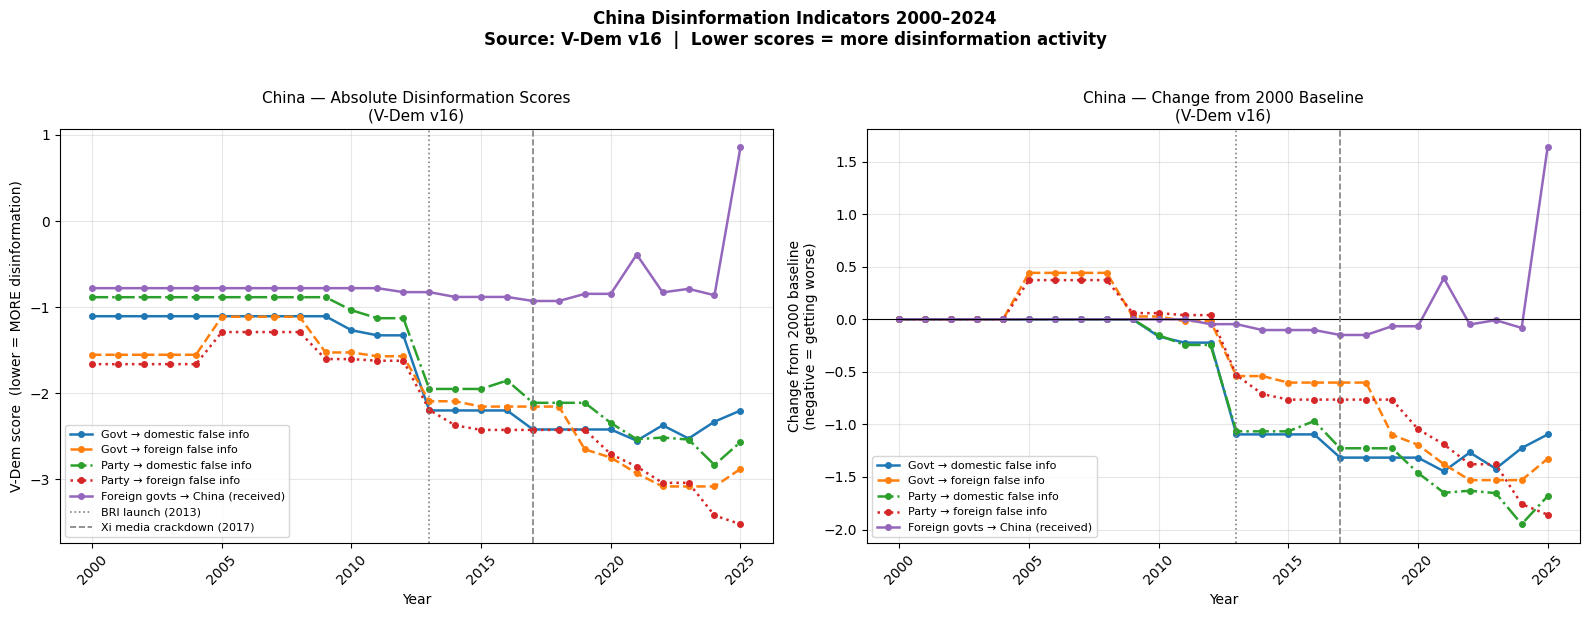

In [5]:
# absolute scores with proper axis explanation
#
# V-Dem scale explanation (important for interpreting):
# These variables are measured on an interval scale where:
#   Higher values (toward +4) = disinformation LESS common / LESS severe
#   Lower values (toward -4)  = disinformation MORE common / MORE severe
# So a DOWNWARD trend is bad — it means MORE disinformation activity.
# China-only view first, matching your original cell.

china = df[df['country_name'] == 'China'].sort_values('year')

cols_to_plot = ['v2smgovdom', 'v2smgovab', 'v2smpardom', 'v2smparab', 'v2smfordom']
labels = {
    'v2smgovdom': 'Govt → domestic false info',
    'v2smgovab':  'Govt → foreign false info',
    'v2smpardom': 'Party → domestic false info',
    'v2smparab':  'Party → foreign false info',
    'v2smfordom': 'Foreign govts → China (received)',
}
line_styles = ['-', '--', '-.', ':', '-']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: absolute scores
ax = axes[0]
for col, ls in zip(cols_to_plot, line_styles):
    ax.plot(china['year'], china[col], label=labels[col],
            marker='o', markersize=4, linestyle=ls, linewidth=1.8)

ax.axvline(2013, color='gray', linestyle=':', linewidth=1.2,
           label='BRI launch (2013)')
ax.axvline(2017, color='gray', linestyle='--', linewidth=1.2,
           label='Xi media crackdown (2017)')
ax.set_xlabel('Year')
ax.set_ylabel('V-Dem score  (lower = MORE disinformation)')
ax.set_title("China — Absolute Disinformation Scores\n(V-Dem v16)", fontsize=11)
ax.legend(fontsize=8, loc='lower left')
ax.grid(alpha=0.3)
ax.tick_params(axis='x', rotation=45)

# Right: change from 2000 baseline (your original approach — useful to keep)
ax2 = axes[1]
for col, ls in zip(cols_to_plot, line_styles):
    baseline = china[china['year'] == china['year'].min()][col].values[0]
    ax2.plot(china['year'], china[col] - baseline, label=labels[col],
             marker='o', markersize=4, linestyle=ls, linewidth=1.8)

ax2.axhline(0, color='black', linewidth=0.8)
ax2.axvline(2013, color='gray', linestyle=':', linewidth=1.2)
ax2.axvline(2017, color='gray', linestyle='--', linewidth=1.2)
ax2.set_xlabel('Year')
ax2.set_ylabel('Change from 2000 baseline\n(negative = getting worse)')
ax2.set_title("China — Change from 2000 Baseline\n(V-Dem v16)", fontsize=11)
ax2.legend(fontsize=8, loc='lower left')
ax2.grid(alpha=0.3)
ax2.tick_params(axis='x', rotation=45)

plt.suptitle(
    "China Disinformation Indicators 2000–2024\n"
    "Source: V-Dem v16  |  Lower scores = more disinformation activity",
    fontsize=12, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.show()

#### Source: 

Coppedge, Michael, John Gerring, Carl Henrik Knutsen, Staffan I. Lindberg, Jan Teorell, David Altman, Fabio Angiolillo, Michael Bernhard, Agnes Cornell, M. Steven Fish, Linnea Fox, Lisa Gastaldi, Haakon Gjerløw, Adam Glynn, Ana Good God, Allen Hicken, Katrin Kinzelbach, Joshua Krusell, Kyle L. Marquardt, Kelly McMann, Valeriya Mechkova, Juraj Medzi horsky, Anja Neundorf, Pamela Paxton, Daniel Pemstein, Josefine Pernes, Johannes von R ̈omer, Brigitte Seim, Rachel Sigman, Svend-Erik Skaaning, Jeffrey Staton, Aksel Sundstr ̈om, Marcus Tannenberg, Eitan Tzelgov, Yi-ting Wang, Tore Wig, Steven Wilson and Daniel Ziblatt. 2026. “V-Dem [Country-Year/Country-Date] Dataset v16” Varieties of Democracy (V-Dem) Project. https://doi.org/10.23696/vdemds26. 

and: 

Pemstein, Daniel, Kyle L. Marquardt, Eitan Tzelgov, Yi-ting Wang, Juraj Medzihorsky, Joshua Krusell, Farhad Miri, and Johannes von R ̈omer. 2026. “The V-Dem Measurement Model: La-tent Variable Analysis for Cross-National and Cross-Temporal Expert-Coded Data”. V-Dem Working Paper No. 21. 11th edition. University of Gothenburg: Varieties of Democracy Institute

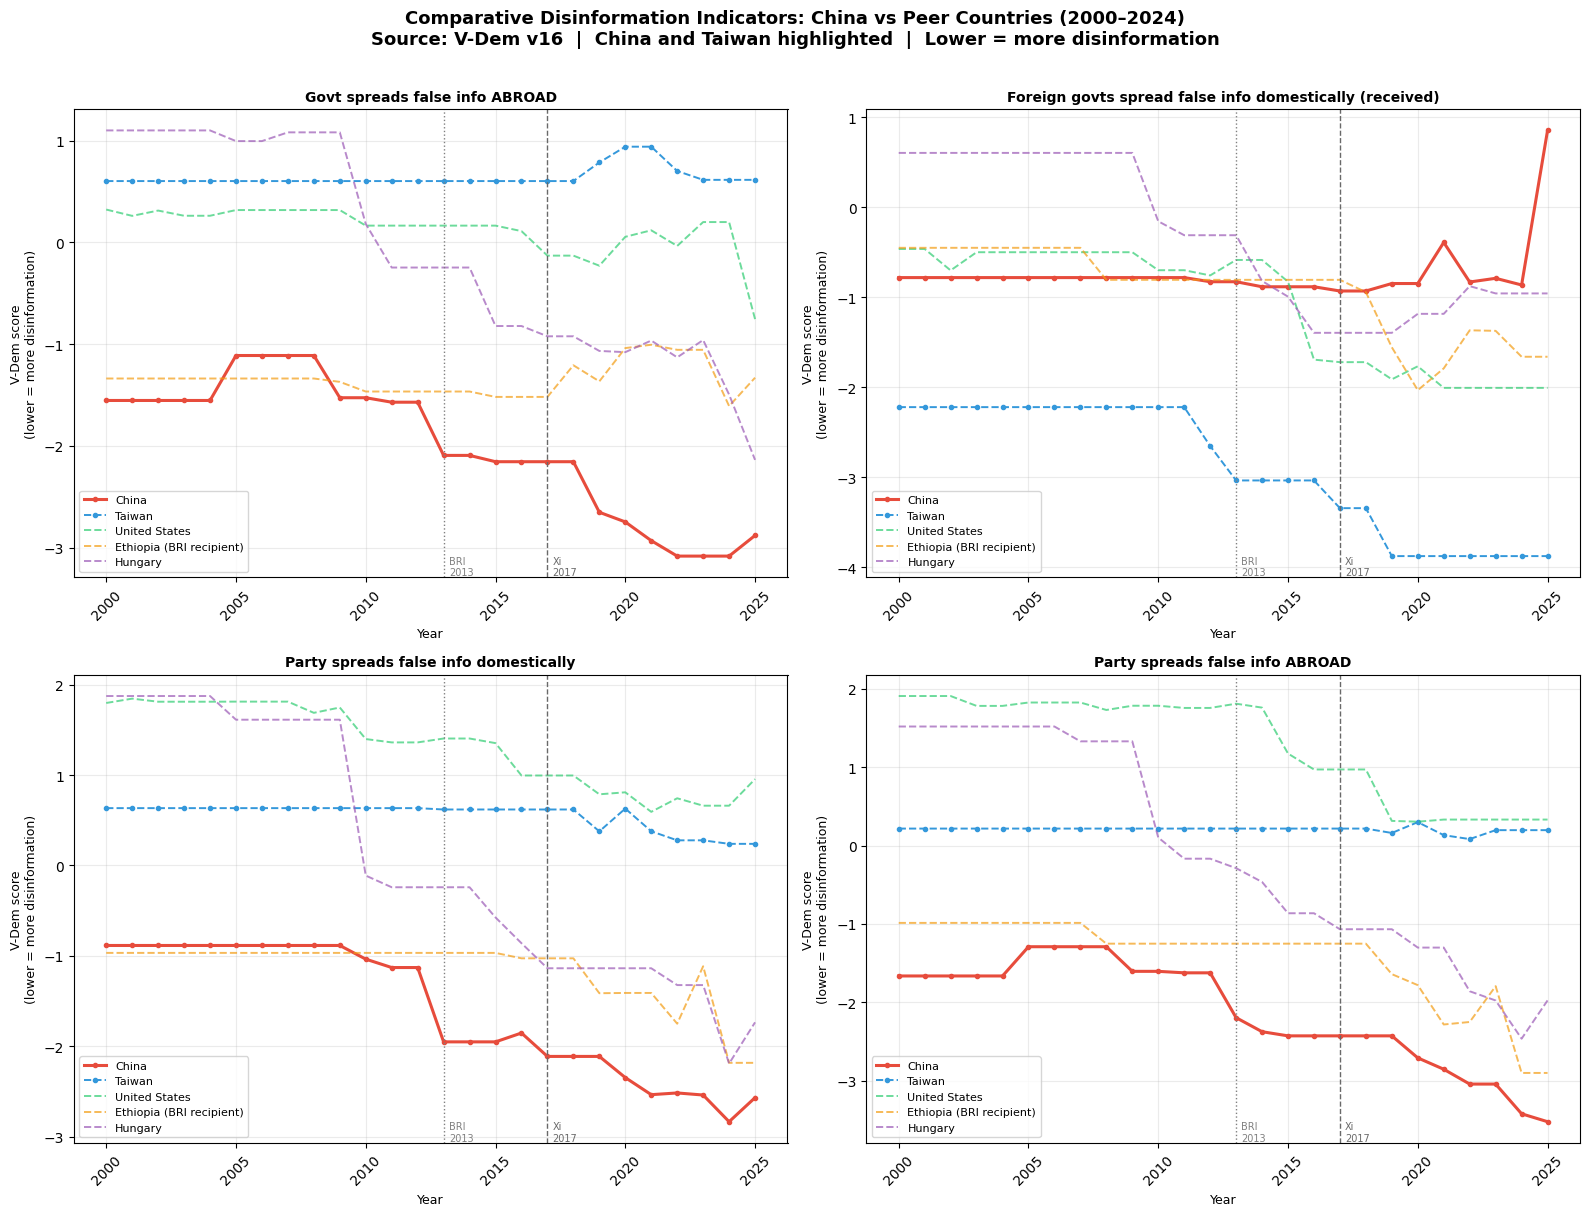


READING GUIDE:
  Top-left:  China's outbound disinformation — does it increase after 2013?
  Top-right: Taiwan's received foreign interference — does it worsen?
             If China (top-left) rises while Taiwan (top-right) falls,
             that is paired empirical evidence for the thesis argument.
  Bottom:    Domestic CCP narrative control — context for your Weibo analysis.


In [ ]:
"""
# Comparative country analysis
#
# This is the key analytical contribution — it shows China is an outlier, not just deteriorating in absolute terms but diverging from peer countries.
# This directly supports the thesis argument that Chinese disinformation is systematic and state-directed, not a general global trend.
"""
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

country_colors = {
    'China':                      '#e74c3c',   # red — the actor
    'Taiwan':                     '#3498db',   # blue — primary target
    'United States of America':   '#2ecc71',   # green — comparison democracy
    'Ethiopia':                   '#f39c12',   # orange — BRI recipient
    'Hungary':                    '#9b59b6',   # purple — backsliding democracy
}

country_labels = {
    'China':                      'China',
    'Taiwan':                     'Taiwan',
    'United States of America':   'United States',
    'Ethiopia':                   'Ethiopia (BRI recipient)',
    'Hungary':                    'Hungary',
}

plot_configs = [
    ('v2smgovab',  'Govt spreads false info ABROAD',
     'axes[0,0]',
     'China\'s score here measures its external disinformation output.\n'
     'A downward trend = increasing foreign disinformation activity.'),

    ('v2smfordom', 'Foreign govts spread false info domestically (received)',
     'axes[0,1]',
     'Taiwan\'s score here measures Chinese operations targeting Taiwan.\n'
     'A downward trend = increasing foreign interference experienced.'),

    ('v2smpardom', 'Party spreads false info domestically',
     'axes[1,0]',
     'Measures domestic CCP narrative control.\n'
     'Context for the 50-cent army and Weibo network analyses.'),

    ('v2smparab',  'Party spreads false info ABROAD',
     'axes[1,1]',
     'Measures CCP\'s international propaganda apparatus.\n'
     'Connects to wolf-warrior diplomacy chapter.'),
]

for (col, title, ax_str, note), ax in zip(
        plot_configs,
        [axes[0,0], axes[0,1], axes[1,0], axes[1,1]]):

    for country in COUNTRIES:
        cdata = df[df['country_name'] == country].sort_values('year')
        if cdata.empty or col not in cdata.columns:
            continue
        ax.plot(
            cdata['year'], cdata[col],
            label=country_labels[country],
            color=country_colors[country],
            linewidth=2.2 if country == 'China' else 1.4,
            linestyle='-' if country == 'China' else '--',
            marker='o' if country in ('China', 'Taiwan') else None,
            markersize=3,
            alpha=1.0 if country in ('China', 'Taiwan') else 0.7
        )

    # Mark key events
    ax.axvline(2013, color='gray', linestyle=':', linewidth=1,
               label='_BRI launch')
    ax.axvline(2017, color='dimgray', linestyle='--', linewidth=1,
               label='_Xi crackdown')
    ax.text(2013.2, ax.get_ylim()[0] if ax.get_ylim()[0] > -10 else -3.5,
            'BRI\n2013', fontsize=7, color='gray', va='bottom')
    ax.text(2017.2, ax.get_ylim()[0] if ax.get_ylim()[0] > -10 else -3.5,
            'Xi\n2017', fontsize=7, color='dimgray', va='bottom')

    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_xlabel('Year', fontsize=9)
    ax.set_ylabel('V-Dem score\n(lower = more disinformation)', fontsize=9)
    ax.legend(fontsize=8, loc='lower left')
    ax.grid(alpha=0.25)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle(
    "Comparative Disinformation Indicators: China vs Peer Countries (2000–2024)\n"
    "Source: V-Dem v16  |  China and Taiwan highlighted  |  Lower = more disinformation",
    fontsize=13, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.show()

print("\nREADING GUIDE:")
print("  Top-left:  China's outbound disinformation — does it increase after 2013?")
print("  Top-right: Taiwan's received foreign interference — does it worsen?")
print("             If China (top-left) rises while Taiwan (top-right) falls,")
print("             that is paired empirical evidence for the thesis argument.")
print("  Bottom:    Domestic CCP narrative control — context for your Weibo analysis.")

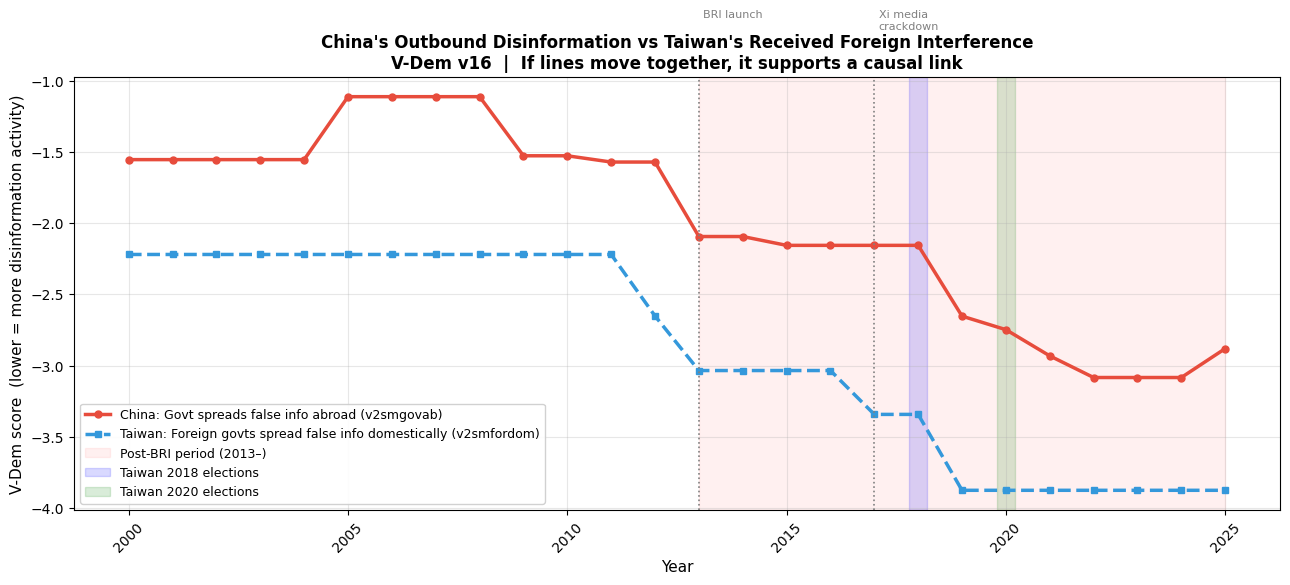

CORRELATION: China outbound ↔ Taiwan received
  Pearson r:  0.9603  (p=0.0000)
  Spearman ρ: 0.9385  (p=0.0000)

  Interpretation:
  Strong positive correlation — as China's outbound
  disinformation worsens, Taiwan's received interference
  worsens proportionally. This is quantitative support for
  the thesis claim that China targets Taiwan specifically.


In [ ]:
"""
This plots China's outbound disinformation (v2smgovab) against Taiwan's received foreign interference (v2smfordom) on the same axis.
If the two lines mirror each other — China goes down as Taiwan goes down — that is quantitative evidence for the causal claim your thesis makes.
"""

china = df[df['country_name'] == 'China'].sort_values('year')
taiwan = df[df['country_name'] == 'Taiwan'].sort_values('year')

# Align on common years
common_years = set(china['year']) & set(taiwan['year'])
china_aligned = china[china['year'].isin(common_years)].sort_values('year')
taiwan_aligned = taiwan[taiwan['year'].isin(common_years)].sort_values('year')

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(china_aligned['year'], china_aligned['v2smgovab'],
        color='#e74c3c', linewidth=2.5, marker='o', markersize=5,
        label="China: Govt spreads false info abroad (v2smgovab)")

ax.plot(taiwan_aligned['year'], taiwan_aligned['v2smfordom'],
        color='#3498db', linewidth=2.5, marker='s', markersize=5,
        linestyle='--',
        label="Taiwan: Foreign govts spread false info domestically (v2smfordom)")

# Shade the post-BRI period
ax.axvspan(2013, china_aligned['year'].max(),
           alpha=0.06, color='red', label='Post-BRI period (2013–)')

# Shade 2018 and 2020 elections
ax.axvspan(2017.8, 2018.2, alpha=0.15, color='blue',
           label='Taiwan 2018 elections')
ax.axvspan(2019.8, 2020.2, alpha=0.15, color='green',
           label='Taiwan 2020 elections')

# Key event lines
for year, label_text in [(2013, 'BRI launch'), (2017, 'Xi media\ncrackdown')]:
    ax.axvline(year, color='gray', linestyle=':', linewidth=1.2)
    ax.text(year + 0.1, ax.get_ylim()[1] * 0.95 if ax.get_ylim()[1] > 0 else -0.5,
            label_text, fontsize=8, color='gray', va='top')

ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('V-Dem score  (lower = more disinformation activity)', fontsize=11)
ax.set_title(
    "China's Outbound Disinformation vs Taiwan's Received Foreign Interference\n"
    "V-Dem v16  |  If lines move together, it supports a causal link",
    fontsize=12, fontweight='bold'
)
ax.legend(fontsize=9, loc='lower left', framealpha=0.9)
ax.grid(alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# --- Correlation between the two series ---
from scipy.stats import pearsonr, spearmanr

pearson_r, pearson_p = pearsonr(
    china_aligned['v2smgovab'],
    taiwan_aligned['v2smfordom']
)
spearman_r, spearman_p = spearmanr(
    china_aligned['v2smgovab'],
    taiwan_aligned['v2smfordom']
)

print("=" * 55)
print("CORRELATION: China outbound ↔ Taiwan received")
print("=" * 55)
print(f"  Pearson r:  {pearson_r:.4f}  (p={pearson_p:.4f})")
print(f"  Spearman ρ: {spearman_r:.4f}  (p={spearman_p:.4f})")
print()
print("  Interpretation:")
if pearson_r > 0.5 and pearson_p < 0.05:
    print("  Strong positive correlation — as China's outbound")
    print("  disinformation worsens, Taiwan's received interference")
    print("  worsens proportionally. This is quantitative support for")
    print("  the thesis claim that China targets Taiwan specifically.")
elif pearson_r > 0 and pearson_p < 0.05:
    print("  Moderate positive correlation — directionally consistent")
    print("  with the thesis argument but not definitive on its own.")
else:
    print("  Weak or non-significant correlation. The V-Dem measures")
    print("  may be too aggregated to capture the bilateral relationship.")
    print("  Supplement with the Twitter IO archive analysis.")